# Project Title

In [1]:
# ======================================================================
# PROJECT: PREDICTING SLEEP DISORDERS
# Author: Rahit Saha
# Objective:
# Predict Sleep Disorder Category:
#     0 = None
#     1 = Insomnia
#     2 = Sleep Apnea
# ======================================================================

# Import Libraries

In [2]:
import warnings
warnings.filterwarnings('ignore')

# Data Handling
import pandas as pd
import numpy as np

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Sklearn
from sklearn.model_selection import (
    train_test_split,
    GridSearchCV,
    StratifiedKFold,
    cross_val_score
)

from sklearn.preprocessing import (
    LabelEncoder,
    StandardScaler
)

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder

# Models
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

# Metrics
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

plt.style.use('seaborn-v0_8')
sns.set_palette("Set2")

# Load Dataset

In [3]:
df = pd.read_csv('Sleep_health_and_lifestyle_dataset.csv')

df.head()

,Person ID,Gender,Age,Occupation,Sleep Duration,Quality of Sleep,Physical Activity Level,Stress Level,BMI Category,Blood Pressure,Heart Rate,Daily Steps,Sleep Disorder
0,1,Male,27,Software Engineer,6.1,6,42,6,Overweight,126/83,77,4200,NaN
1,2,Male,28,Doctor,6.2,6,60,8,Normal,125/80,75,10000,NaN
2,3,Male,28,Doctor,6.2,6,60,8,Normal,125/80,75,10000,NaN
3,4,Male,28,Sales Representative,5.9,4,30,8,Obese,140/90,85,3000,Sleep Apnea
4,5,Male,28,Sales Representative,5.9,4,30,8,Obese,140/90,85,3000,Sleep Apnea


# Basic Information

In [4]:
print("Shape :", df.shape)

print("\n")
display(df.sample(5))

print("\nData Types")
display(df.dtypes)

print("\nMissing Values")
display(df.isnull().sum())


Shape : (374, 13)




,Person ID,Gender,Age,Occupation,Sleep Duration,Quality of Sleep,Physical Activity Level,Stress Level,BMI Category,Blood Pressure,Heart Rate,Daily Steps,Sleep Disorder
234,235,Female,44,Teacher,6.6,7,45,4,Overweight,135/90,65,6000,Insomnia
338,339,Female,54,Engineer,8.5,9,30,3,Normal,125/80,65,5000,NaN
185,186,Female,42,Teacher,6.8,6,45,7,Overweight,130/85,78,5000,Sleep Apnea
277,278,Male,49,Doctor,8.1,9,85,3,Obese,139/91,86,3700,Sleep Apnea
246,247,Male,44,Salesperson,6.3,6,45,7,Overweight,130/85,72,6000,Insomnia



Data Types


,0
Person ID,int64
Gender,object
Age,int64
Occupation,object
Sleep Duration,float64
Quality of Sleep,int64
Physical Activity Level,int64
Stress Level,int64
BMI Category,object
Blood Pressure,object



Missing Values


,0
Person ID,0
Gender,0
Age,0
Occupation,0
Sleep Duration,0
Quality of Sleep,0
Physical Activity Level,0
Stress Level,0
BMI Category,0
Blood Pressure,0


# Statistical Summary

In [5]:
df.describe(include='all')

,Person ID,Gender,Age,Occupation,Sleep Duration,Quality of Sleep,Physical Activity Level,Stress Level,BMI Category,Blood Pressure,Heart Rate,Daily Steps,Sleep Disorder
count,374.000000,374,374.000000,374,374.000000,374.000000,374.000000,374.000000,374,374,374.000000,374.000000,155
unique,NaN,2,NaN,11,NaN,NaN,NaN,NaN,4,25,NaN,NaN,2
top,NaN,Male,NaN,Nurse,NaN,NaN,NaN,NaN,Normal,130/85,NaN,NaN,Sleep Apnea
freq,NaN,189,NaN,73,NaN,NaN,NaN,NaN,195,99,NaN,NaN,78
mean,187.500000,NaN,42.184492,NaN,7.132086,7.312834,59.171123,5.385027,NaN,NaN,70.165775,6816.844920,NaN
std,108.108742,NaN,8.673133,NaN,0.795657,1.196956,20.830804,1.774526,NaN,NaN,4.135676,1617.915679,NaN
min,1.000000,NaN,27.000000,NaN,5.800000,4.000000,30.000000,3.000000,NaN,NaN,65.000000,3000.000000,NaN
25%,94.250000,NaN,35.250000,NaN,6.400000,6.000000,45.000000,4.000000,NaN,NaN,68.000000,5600.000000,NaN
50%,187.500000,NaN,43.000000,NaN,7.200000,7.000000,60.000000,5.000000,NaN,NaN,70.000000,7000.000000,NaN
75%,280.750000,NaN,50.000000,NaN,7.800000,8.000000,75.000000,7.000000,NaN,NaN,72.000000,8000.000000,NaN


# Duplicate Analysis

In [6]:
duplicates = df.duplicated().sum()

print(f"Duplicate Rows : {duplicates}")

Duplicate Rows : 0


# Data Cleaning

### Drop Person ID

In [7]:
df.drop('Person ID', axis=1, inplace=True)

### Split Blood Pressure

In [8]:
df[['Systolic_BP','Diastolic_BP']] = \
df['Blood Pressure'].str.split("/", expand=True)

df['Systolic_BP'] = df['Systolic_BP'].astype(int)
df['Diastolic_BP'] = df['Diastolic_BP'].astype(int)

df.drop('Blood Pressure', axis=1, inplace=True)

### Standardize BMI Category

In [9]:
df['BMI Category'] = df['BMI Category'].replace({
    'Normal Weight':'Normal'
})

df['BMI Category'].value_counts()

,count
BMI Category,
Normal,216
Overweight,148
Obese,10


# Target Variable Analysis

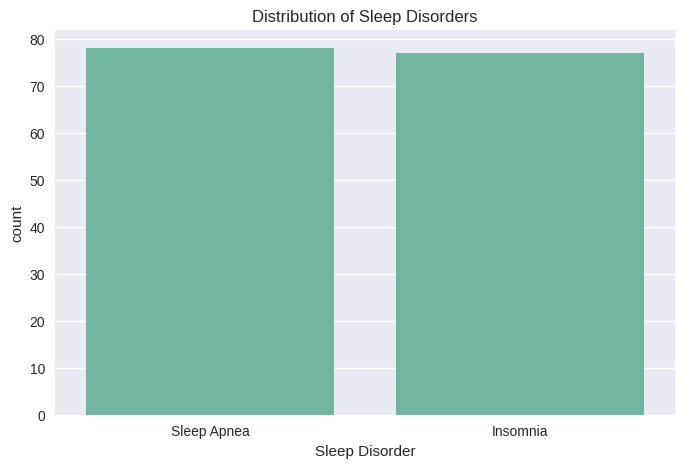

In [10]:
plt.figure(figsize=(8,5))

sns.countplot(
    x='Sleep Disorder',
    data=df
)

plt.title('Distribution of Sleep Disorders')
plt.show()

from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()
df['Sleep Disorder'] = le.fit_transform(df['Sleep Disorder'])



# Univariate Analysis

### Age Distribution

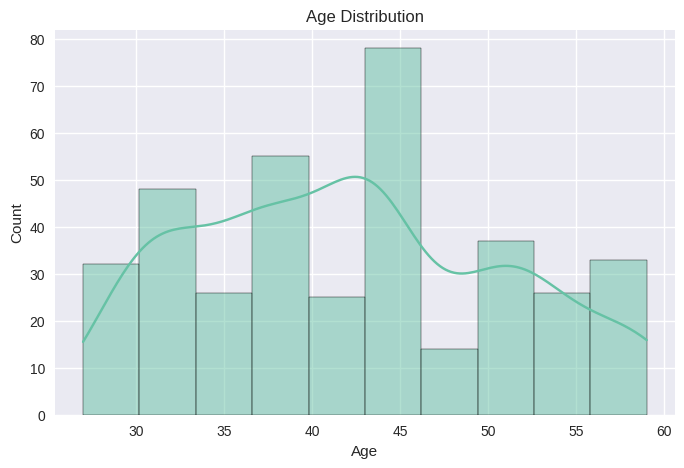

In [11]:
plt.figure(figsize=(8,5))
sns.histplot(df['Age'], kde=True)

plt.title("Age Distribution")
plt.show()

### Sleep Duration

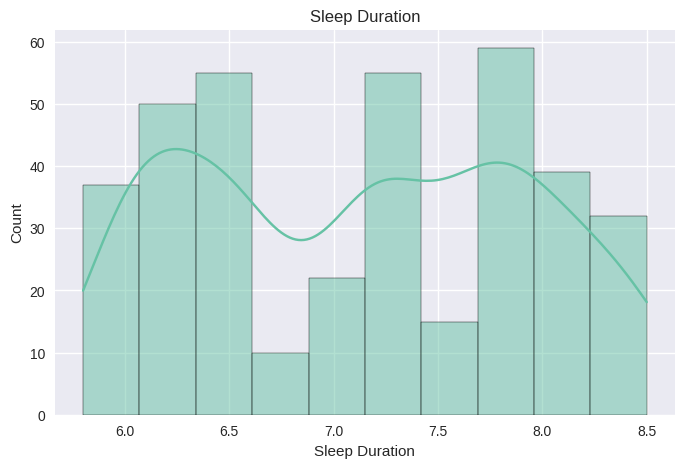

In [12]:
plt.figure(figsize=(8,5))
sns.histplot(df['Sleep Duration'], kde=True)

plt.title("Sleep Duration")
plt.show()

df['Sleep_Efficiency'] = (
    df['Quality of Sleep'] /
    df['Sleep Duration']
)

### Stress Level

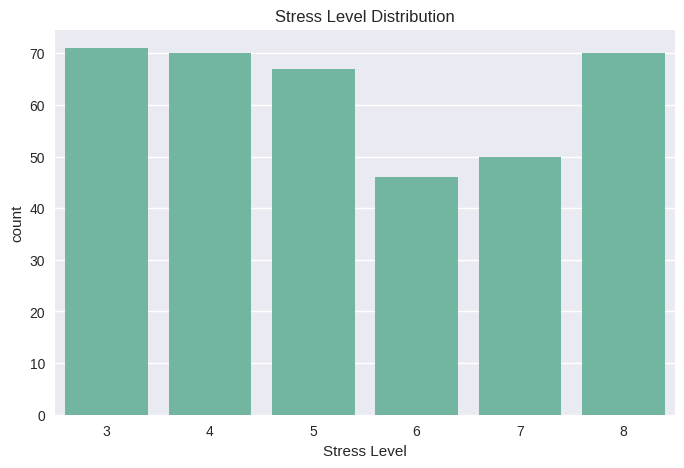

In [13]:
plt.figure(figsize=(8,5))
sns.countplot(x='Stress Level', data=df)

plt.title("Stress Level Distribution")
plt.show()

# Key Focus Area 1

# Impact of Gender on Sleep Disorders

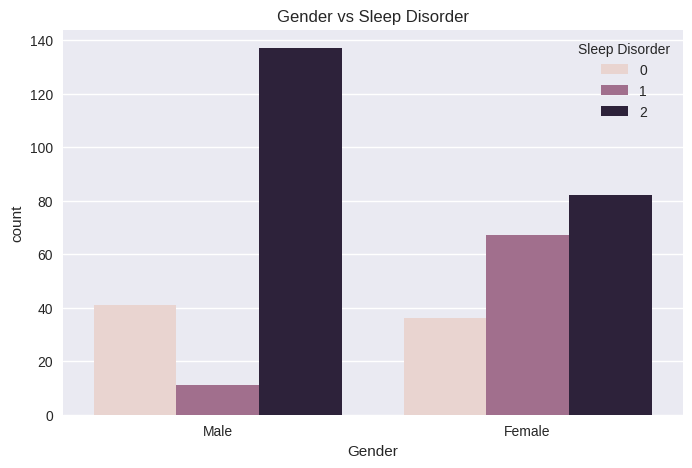

In [14]:
plt.figure(figsize=(8,5))

sns.countplot(
    x='Gender',
    hue='Sleep Disorder',
    data=df
)

plt.title("Gender vs Sleep Disorder")
plt.show()

# Age vs Sleep Disorder

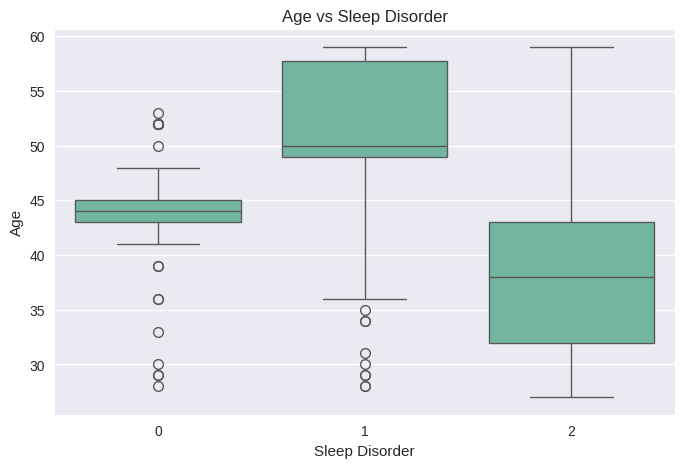

In [15]:
plt.figure(figsize=(8,5))

sns.boxplot(
    x='Sleep Disorder',
    y='Age',
    data=df
)

plt.title("Age vs Sleep Disorder")
plt.show()

# Occupation vs Sleep Disorder

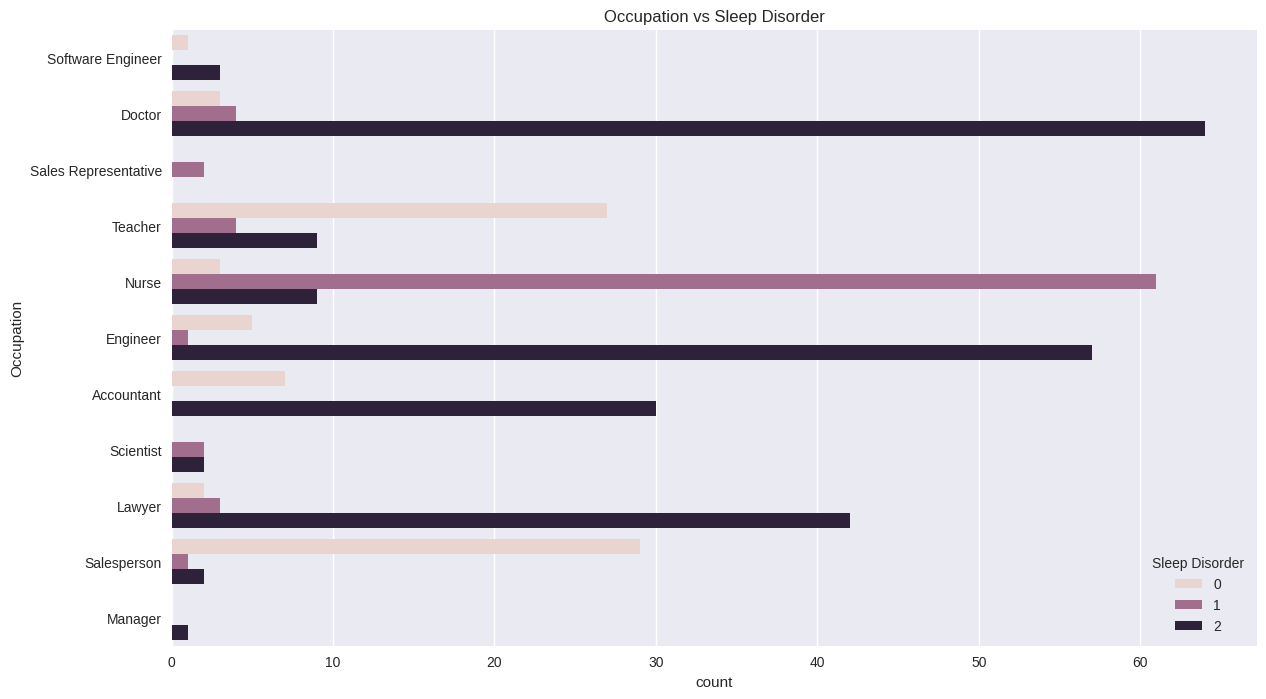

In [16]:
plt.figure(figsize=(14,8))

sns.countplot(
    y='Occupation',
    hue='Sleep Disorder',
    data=df
)

plt.title("Occupation vs Sleep Disorder")
plt.show()

# Key Focus Area 2



# Activity Intensity

In [17]:
df['Steps_per_Activity'] = (
    df['Daily Steps'] /
    (df['Physical Activity Level'] + 1)
)


# Physical Activity vs Sleep Disorder

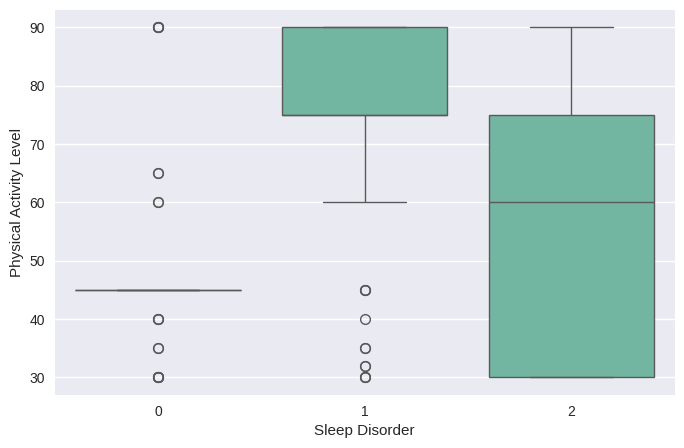

In [18]:
plt.figure(figsize=(8,5))

sns.boxplot(
    x='Sleep Disorder',
    y='Physical Activity Level',
    data=df
)

plt.show()

# Stress Level vs Sleep Disorder

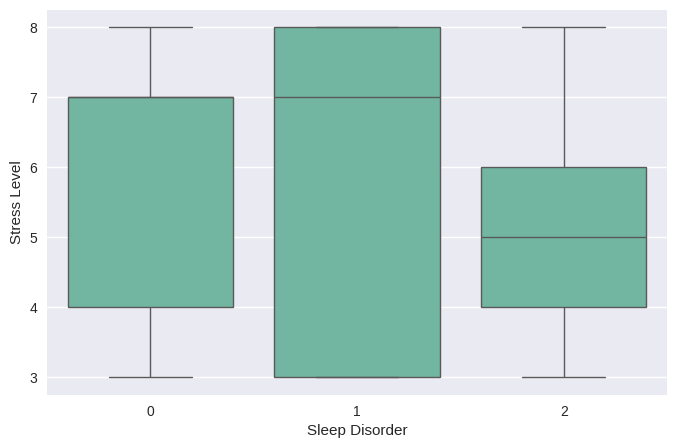

In [19]:
plt.figure(figsize=(8,5))

sns.boxplot(
    x='Sleep Disorder',
    y='Stress Level',
    data=df
)

plt.show()

# Daily Steps vs Sleep Disorder

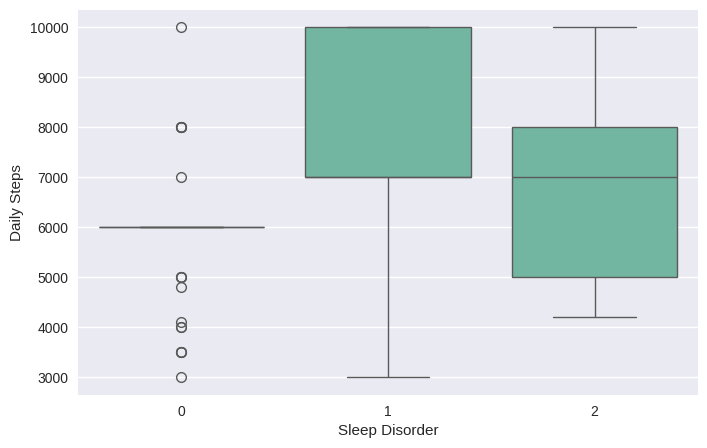

In [20]:
plt.figure(figsize=(8,5))

sns.boxplot(
    x='Sleep Disorder',
    y='Daily Steps',
    data=df
)

plt.show()

# Key Focus Area 3

# BMI Category

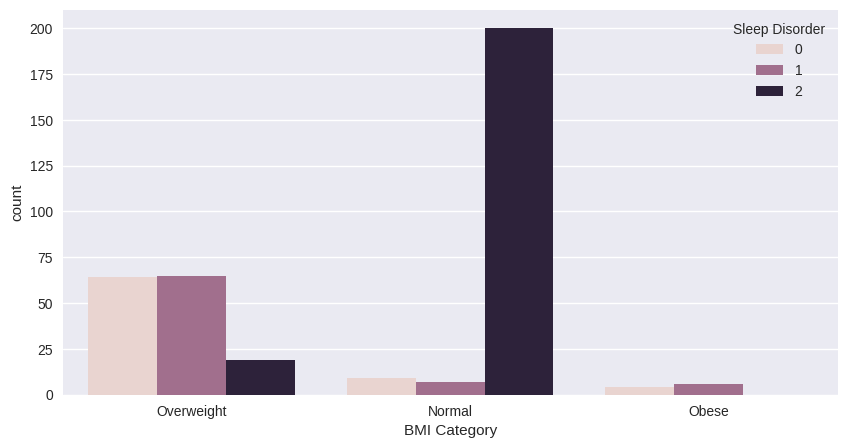

In [21]:
plt.figure(figsize=(10,5))

sns.countplot(
    x='BMI Category',
    hue='Sleep Disorder',
    data=df
)

plt.show()

# Systolic BP

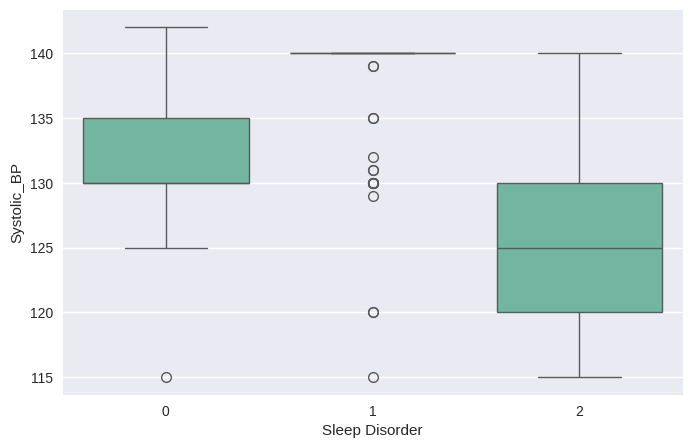

In [22]:
plt.figure(figsize=(8,5))

sns.boxplot(
    x='Sleep Disorder',
    y='Systolic_BP',
    data=df
)

plt.show()

df['Pulse_Pressure'] = df['Systolic_BP'] - df['Diastolic_BP']
df['Mean_Arterial_Pressure'] = (
    df['Diastolic_BP'] +
    (df['Systolic_BP'] - df['Diastolic_BP']) / 3
)


# Heart Rate

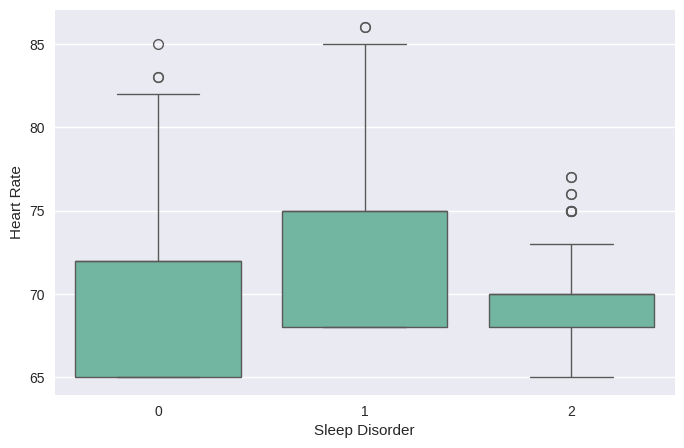

In [23]:
plt.figure(figsize=(8,5))

sns.boxplot(
    x='Sleep Disorder',
    y='Heart Rate',
    data=df
)

plt.show()

# Key Focus Area 4

# Sleep Duration vs Sleep Disorder

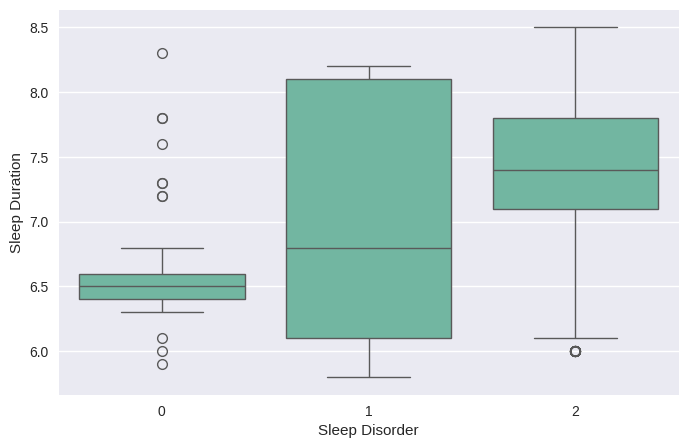

In [24]:
plt.figure(figsize=(8,5))

sns.boxplot(
    x='Sleep Disorder',
    y='Sleep Duration',
    data=df
)

plt.show()

# Quality of Sleep

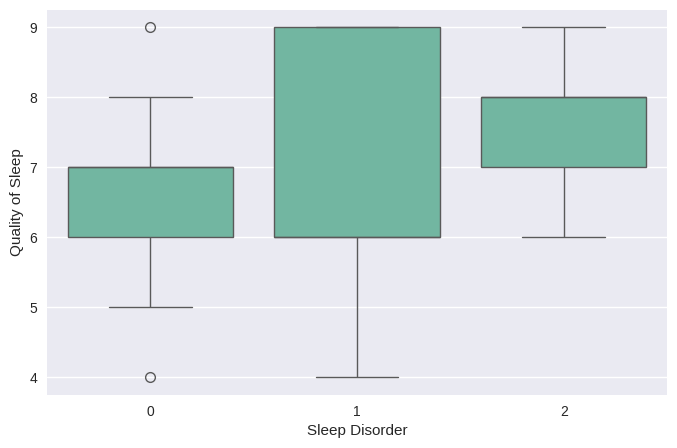

In [25]:
plt.figure(figsize=(8,5))

df['Sleep_Efficiency'] = (
    df['Quality of Sleep'] /
    df['Sleep Duration']
)
sns.boxplot(
    x='Sleep Disorder',
    y='Quality of Sleep',
    data=df
)

plt.show()

# Correlation Heatmap

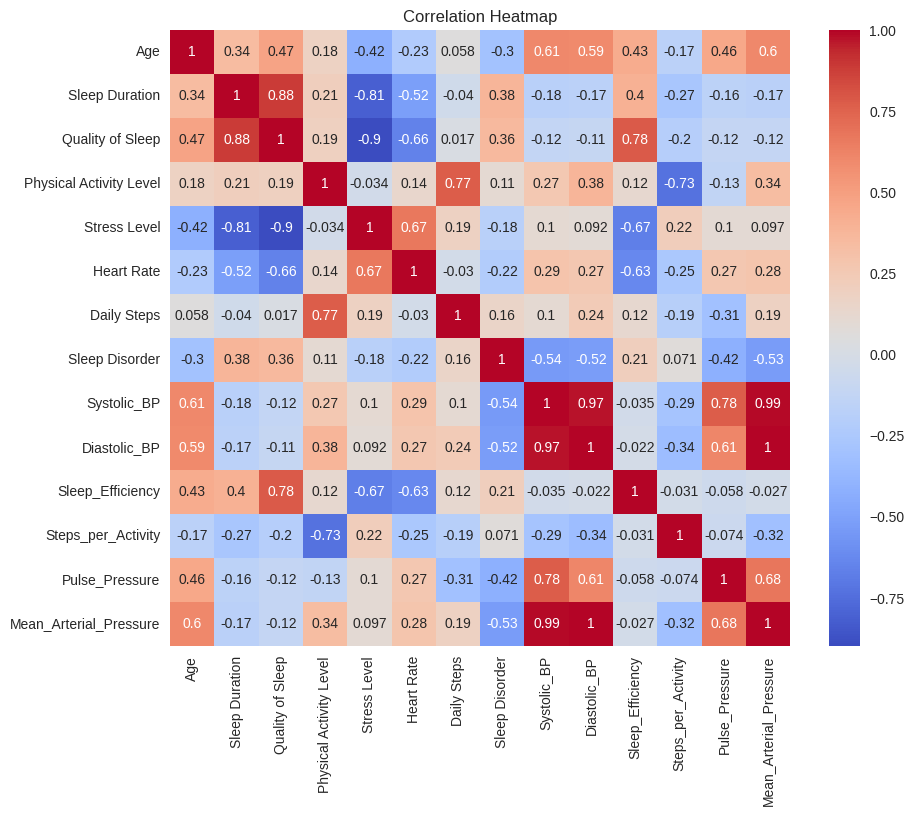

In [26]:
num_df = df.select_dtypes(include=np.number)

plt.figure(figsize=(10,8))

sns.heatmap(
    num_df.corr(),
    annot=True,
    cmap='coolwarm'
)

plt.title("Correlation Heatmap")
plt.show()

# Label Encoding Target

In [27]:
le = LabelEncoder()

df['Sleep Disorder'] = \
le.fit_transform(df['Sleep Disorder'])

mapping = dict(zip(
    le.classes_,
    le.transform(le.classes_)
))

print(mapping)

{np.int64(0): np.int64(0), np.int64(1): np.int64(1), np.int64(2): np.int64(2)}


# Train Test Split

In [28]:
X = df.drop('Sleep Disorder', axis=1)
y = df['Sleep Disorder']

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Preprocessing Pipeline

In [29]:
categorical_features = [
    'Gender',
    'Occupation',
    'BMI Category'
]

numerical_features = [
    col for col in X.columns
    if col not in categorical_features
]

preprocessor = ColumnTransformer(

    transformers=[

        (
            'num',
            Pipeline([
                ('imputer',
                 SimpleImputer(strategy='median')),
                ('scaler',
                 StandardScaler())
            ]),
            numerical_features
        ),

        (
            'cat',
            Pipeline([
                ('imputer',
                 SimpleImputer(strategy='most_frequent')),
                ('onehot',
                 OneHotEncoder(handle_unknown='ignore'))
            ]),
            categorical_features
        )
    ]
)

# Logistic Regression

In [30]:
log_model = Pipeline([
    ('prep', preprocessor),
    ('model', LogisticRegression(max_iter=1000))
])

log_model.fit(X_train,y_train)

log_pred = log_model.predict(X_test)

# Evaluation Function

In [31]:
def evaluate_model(name,y_true,y_pred):

    print("="*50)
    print(name)
    print("="*50)

    print("Accuracy :",
          accuracy_score(y_true,y_pred))

    print("Precision :",
          precision_score(
              y_true,
              y_pred,
              average='weighted'))

    print("Recall :",
          recall_score(
              y_true,
              y_pred,
              average='weighted'))

    print("F1 Score :",
          f1_score(
              y_true,
              y_pred,
              average='weighted'))

    print("\nClassification Report\n")

    print(classification_report(
        y_true,
        y_pred
    ))

# Call the function outside the function definition block
evaluate_model(
    "Logistic Regression",
    y_test,
    log_pred
)

Logistic Regression
Accuracy : 0.92
Precision : 0.9220428636570908
Recall : 0.92
F1 Score : 0.9207802159526299

Classification Report

              precision    recall  f1-score   support

           0       0.87      0.87      0.87        15
           1       0.82      0.88      0.85        16
           2       0.98      0.95      0.97        44

    accuracy                           0.92        75
   macro avg       0.89      0.90      0.89        75
weighted avg       0.92      0.92      0.92        75



# Decision Tree

In [32]:
dt_model = Pipeline([
    ('prep',preprocessor),

    ('model',
     DecisionTreeClassifier(
         random_state=42
     ))
])

dt_model.fit(X_train,y_train)

dt_pred = dt_model.predict(X_test)

evaluate_model(
    'Decision Tree',
    y_test,
    dt_pred
)

Decision Tree
Accuracy : 0.92
Precision : 0.9226180270557837
Recall : 0.92
F1 Score : 0.9203615127919913

Classification Report

              precision    recall  f1-score   support

           0       0.82      0.93      0.88        15
           1       0.87      0.81      0.84        16
           2       0.98      0.95      0.97        44

    accuracy                           0.92        75
   macro avg       0.89      0.90      0.89        75
weighted avg       0.92      0.92      0.92        75



# Random Forest

In [33]:
rf_model = Pipeline([
    ('prep',preprocessor),

    ('model',
     RandomForestClassifier(
         random_state=42
     ))
])

rf_model.fit(X_train,y_train)

rf_pred = rf_model.predict(X_test)

evaluate_model(
    "Random Forest",
    y_test,
    rf_pred
)

Random Forest
Accuracy : 0.92
Precision : 0.9220428636570908
Recall : 0.92
F1 Score : 0.9207802159526299

Classification Report

              precision    recall  f1-score   support

           0       0.87      0.87      0.87        15
           1       0.82      0.88      0.85        16
           2       0.98      0.95      0.97        44

    accuracy                           0.92        75
   macro avg       0.89      0.90      0.89        75
weighted avg       0.92      0.92      0.92        75



# Confusion Matrix

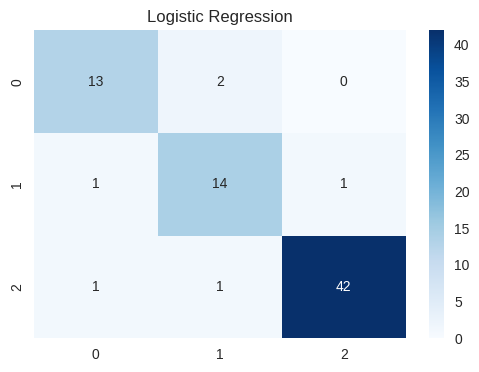

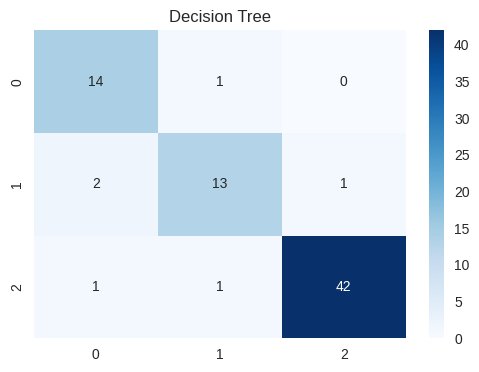

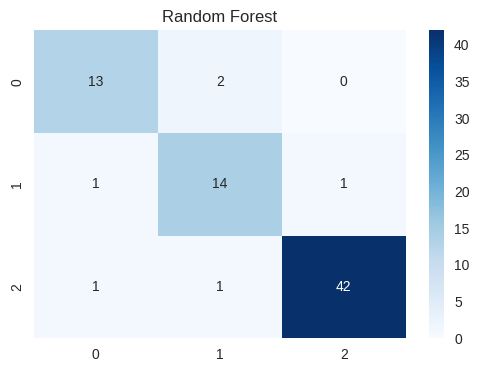

In [34]:
models = {
    "Logistic Regression":log_pred,
    "Decision Tree":dt_pred,
    "Random Forest":rf_pred
}

for name,preds in models.items():

    cm = confusion_matrix(
        y_test,
        preds
    )

    plt.figure(figsize=(6,4))

    sns.heatmap(
        cm,
        annot=True,
        fmt='d',
        cmap='Blues'
    )

    plt.title(name)
    plt.show()

# Cross Validation

In [35]:
from sklearn.model_selection import StratifiedKFold

cv = StratifiedKFold(
    n_splits=10,
    shuffle=True,
    random_state=42
)

rf_scores = cross_val_score(
    rf_model,
    X,
    y,
    cv=cv,
    scoring='accuracy'
)

print("CV Scores")
print(rf_scores)

print("\nMean Accuracy")
print(rf_scores.mean())

CV Scores
[1.         0.86842105 0.94736842 0.97368421 0.86486486 0.91891892
 0.86486486 0.89189189 0.89189189 0.91891892]

Mean Accuracy
0.9140825035561878


# Hyperparameter Tuning

In [36]:
param_grid = {

    'model__n_estimators':[100,200,300],

    'model__max_depth':[5,10,15,None],

    'model__min_samples_split':[2,5,10]
}

In [37]:
grid_rf = GridSearchCV(

    rf_model,

    param_grid,

    cv=5,

    scoring='accuracy',

    n_jobs=-1
)

grid_rf.fit(X_train,y_train)

print(grid_rf.best_params_)

{'model__max_depth': 5, 'model__min_samples_split': 2, 'model__n_estimators': 300}


# Best Random Forest

In [38]:
best_rf = grid_rf.best_estimator_

best_pred = best_rf.predict(X_test)

evaluate_model(
    "Tuned Random Forest",
    y_test,
    best_pred
)

Tuned Random Forest
Accuracy : 0.92
Precision : 0.9226180270557837
Recall : 0.92
F1 Score : 0.9203615127919913

Classification Report

              precision    recall  f1-score   support

           0       0.82      0.93      0.88        15
           1       0.87      0.81      0.84        16
           2       0.98      0.95      0.97        44

    accuracy                           0.92        75
   macro avg       0.89      0.90      0.89        75
weighted avg       0.92      0.92      0.92        75



# Feature Importance

In [39]:
rf_final = best_rf.named_steps['model']

feature_names = best_rf.named_steps[
    'prep'
].get_feature_names_out()

In [40]:
importance = pd.DataFrame({

    'Feature':feature_names,

    'Importance':
    rf_final.feature_importances_
})

importance = importance.sort_values(
    by='Importance',
    ascending=False
).head(15)

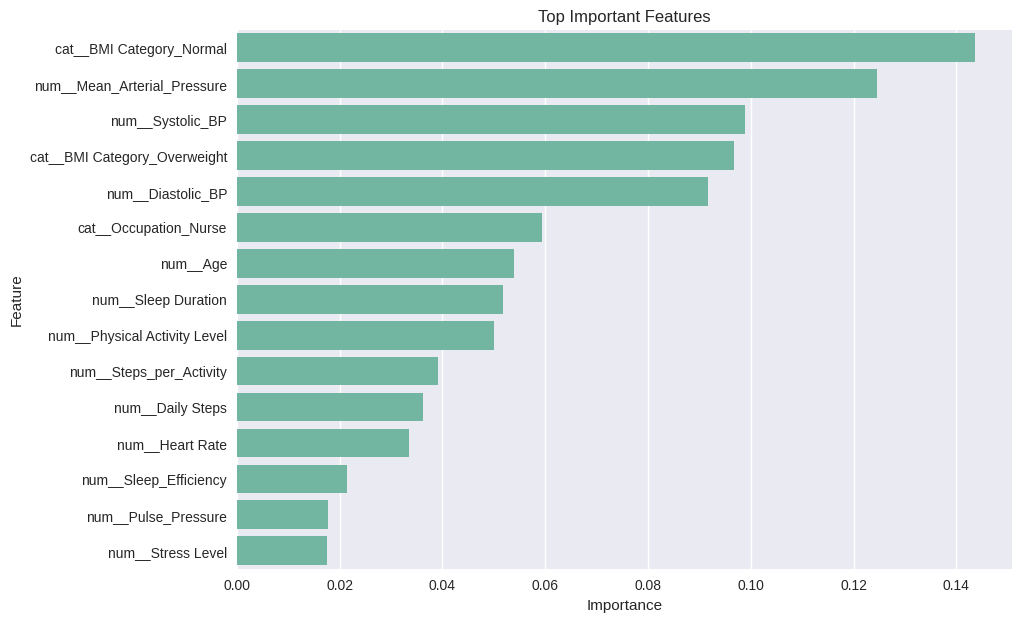

In [41]:
plt.figure(figsize=(10,7))

sns.barplot(

    x='Importance',

    y='Feature',

    data=importance

)

plt.title('Top Important Features')
plt.show()

# Import XGBoost

In [42]:
!pip install xgboost -q

from xgboost import XGBClassifier


# Build XGBoost Pipeline

### Since your target is multiclass:

. Insomnia

. None

. Sleep Apnea

In [43]:
xgb_model = Pipeline([

    ('prep', preprocessor),

    ('model',
     XGBClassifier(

         objective='multi:softprob',

         num_class=3,

         eval_metric='mlogloss',

         random_state=42
     ))
])

# Train Model

In [44]:
xgb_model.fit(
    X_train,
    y_train
)

Pipeline(steps=[('prep',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['Age', 'Sleep Duration',
                                                   'Quality of Sleep',
                                                   'Physical Activity Level',
                                                   'Stress Level', 'Heart Rate',
                                                   'Daily Steps', 'Systolic_BP',
                                                   'Diastolic_BP',
                                                   'Sleep_Efficiency',
                                                   'Steps_per_Activity',
                                                   'Pulse_Pressure',
                                                   'Mean_A...
                               feature_types=None, feature_weights=None,
                               gamma=None, grow_policy=None,
                               importance_type=None,
                               interaction_constraints=None, learning_rate=None,
                               max_bin=None, max_cat_threshold=None,
                               max_cat_to_onehot=None, max_delta_step=None,
                               max_depth=None, max_leaves=None,
                               min_child_weight=None, missing=nan,
                               monotone_constraints=None, multi_strategy=None,
                               n_estimators=None, n_jobs=None, num_class=3, ...))])

# Predictions

In [45]:
xgb_pred = xgb_model.predict(
    X_test
)

# Evaluate XGBoost

In [46]:
evaluate_model(
    "XGBoost",
    y_test,
    xgb_pred
)

XGBoost
Accuracy : 0.9333333333333333
Precision : 0.9346899224806202
Recall : 0.9333333333333333
F1 Score : 0.9337486095661848

Classification Report

              precision    recall  f1-score   support

           0       0.88      0.93      0.90        15
           1       0.88      0.88      0.88        16
           2       0.98      0.95      0.97        44

    accuracy                           0.93        75
   macro avg       0.91      0.92      0.91        75
weighted avg       0.93      0.93      0.93        75



# Confusion Matrix

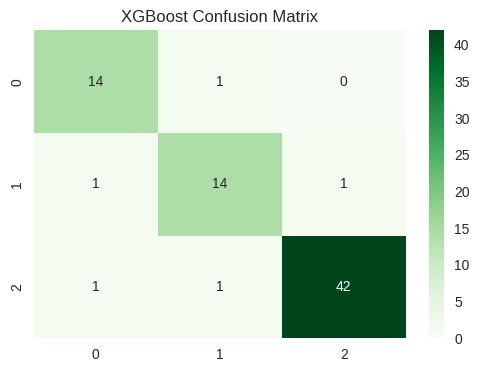

In [47]:
cm = confusion_matrix(
    y_test,
    xgb_pred
)

plt.figure(figsize=(6,4))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Greens'
)

plt.title("XGBoost Confusion Matrix")

plt.show()

# Cross Validation

In [48]:
cv_scores = cross_val_score(

    xgb_model,

    X,

    y,

    cv=5,

    scoring='accuracy'
)

print("Cross Validation Scores")

print(cv_scores)

print("\nMean Accuracy")

print(cv_scores.mean())

Cross Validation Scores
[0.69333333 0.42666667 0.96       0.53333333 0.83783784]

Mean Accuracy
0.6902342342342342


# Hyperparameter Tuning

In [49]:
xgb_param_grid = {
    'model__n_estimators': [200, 300, 500],
    'model__max_depth': [3, 4, 5, 6],
    'model__learning_rate': [0.01, 0.05, 0.1],
    'model__subsample': [0.8, 0.9, 1.0],
    'model__colsample_bytree': [0.8, 0.9, 1.0]
}

xgb_grid = GridSearchCV(
    estimator=xgb_model,
    param_grid=xgb_param_grid,
    scoring='accuracy',
    cv=5,
    n_jobs=-1
)

xgb_grid.fit(
    X_train,
    y_train
)

print(
    xgb_grid.best_params_
)

{'model__colsample_bytree': 0.8, 'model__learning_rate': 0.01, 'model__max_depth': 3, 'model__n_estimators': 200, 'model__subsample': 1.0}


# Best XGBoost Model

In [50]:
best_xgb = xgb_grid.best_estimator_

best_xgb_pred = best_xgb.predict(
    X_test
)

evaluate_model(
    "Tuned XGBoost",
    y_test,
    best_xgb_pred
)

Tuned XGBoost
Accuracy : 0.92
Precision : 0.9226180270557837
Recall : 0.92
F1 Score : 0.9203615127919913

Classification Report

              precision    recall  f1-score   support

           0       0.82      0.93      0.88        15
           1       0.87      0.81      0.84        16
           2       0.98      0.95      0.97        44

    accuracy                           0.92        75
   macro avg       0.89      0.90      0.89        75
weighted avg       0.92      0.92      0.92        75



# XGBoost Feature Importance

In [51]:
feature_names = best_xgb.named_steps[
    'prep'
].get_feature_names_out()

In [52]:
xgb_importance = pd.DataFrame({

    'Feature': feature_names,

    'Importance':
    best_xgb.named_steps[
        'model'
    ].feature_importances_
})

In [53]:
xgb_importance = xgb_importance.sort_values(

    'Importance',

    ascending=False
).head(20)

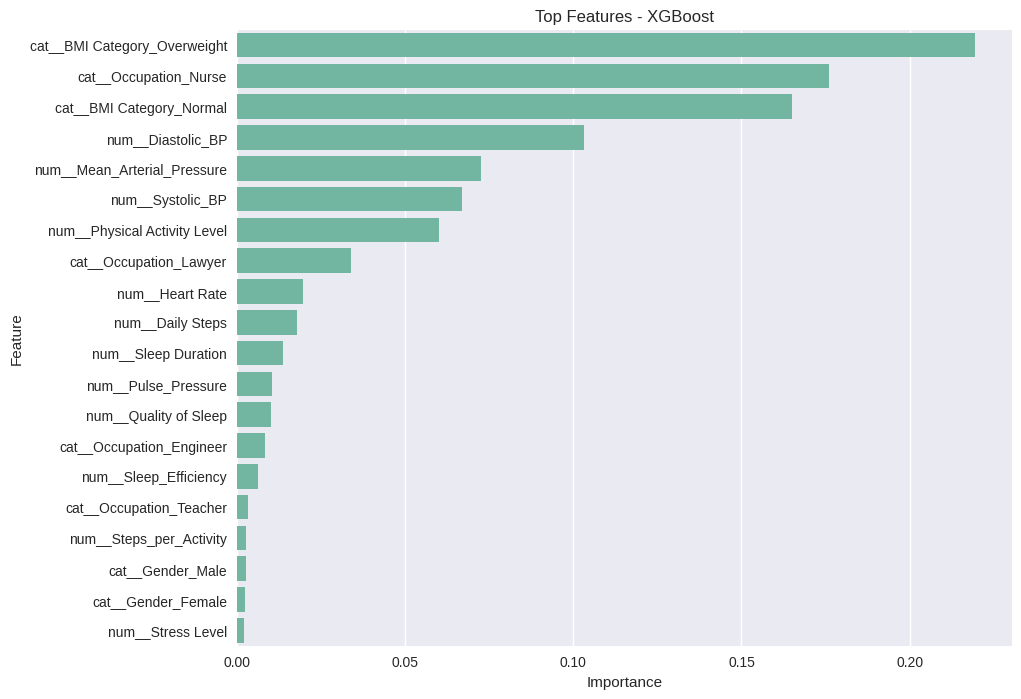

In [54]:
plt.figure(
    figsize=(10,8)
)

sns.barplot(

    data=xgb_importance,

    x='Importance',

    y='Feature'
)

plt.title(
    "Top Features - XGBoost"
)

plt.show()

# SHAP for XGBoost

### Prepare Data

In [55]:
!pip install shap -q
import shap

X_test_processed = best_xgb.named_steps[
    'prep'
].transform(X_test)

### Create Explainer

In [56]:
explainer = shap.TreeExplainer(

    best_xgb.named_steps[
        'model'
    ]
)

### Generate SHAP Values

In [57]:
shap_values = explainer.shap_values(
    X_test_processed
)

# SHAP Summary Plot

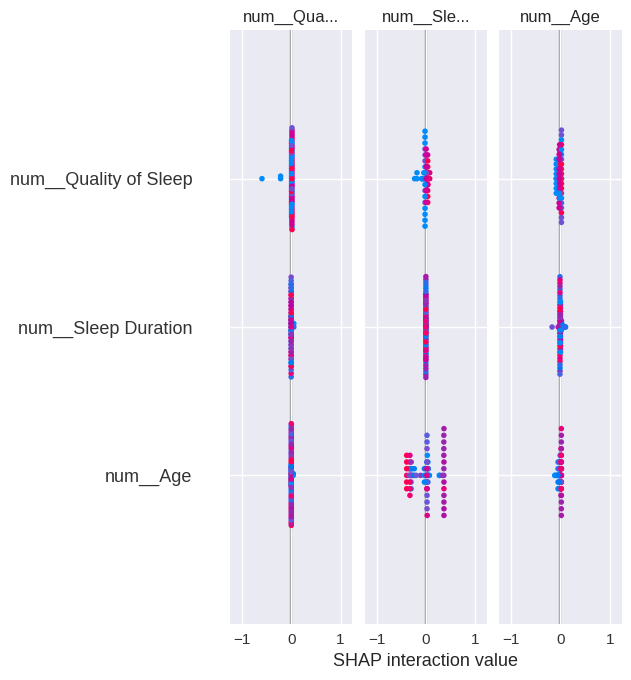

In [58]:
shap.summary_plot(

    shap_values,

    X_test_processed,

    feature_names=feature_names
)

### SHAP Bar Plot

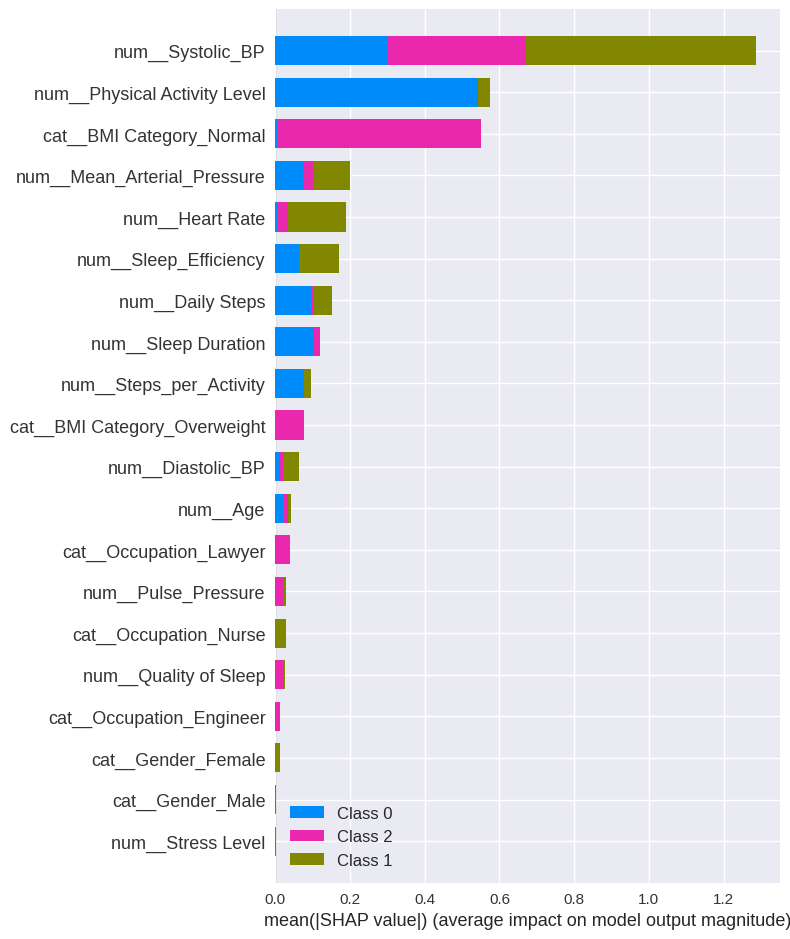

In [59]:
shap.summary_plot(

    shap_values,

    X_test_processed,

    feature_names=feature_names,

    plot_type='bar'
)

# Extract Trained Random Forest

In [60]:
rf_model_explainer = best_rf.named_steps['model']

# Transform Data

### SHAP needs preprocessed data.

In [61]:
X_train_processed = best_rf.named_steps[
    'prep'
].transform(X_train)

X_test_processed = best_rf.named_steps[
    'prep'
].transform(X_test)

# Create Feature Names

In [62]:
feature_names = best_rf.named_steps[
    'prep'
].get_feature_names_out()

# SHAP Explainer

In [63]:
explainer = shap.TreeExplainer(
    rf_model_explainer
)

shap_values = explainer.shap_values(
    X_test_processed
)

# Global Feature Importance

### Shows overall feature influence.

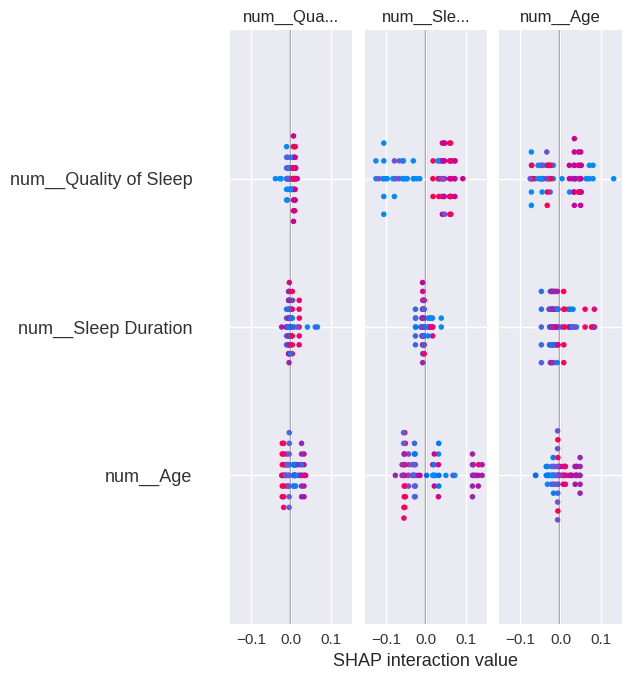

In [64]:
shap.summary_plot(
    shap_values,
    X_test_processed,
    feature_names=feature_names
)

## **Interpretation**

### Red → High Feature Value

### Blue → Low Feature Value

##**Expected influential variables:**

### Sleep Duration

### Quality of Sleep

### Stress Level

### BMI Category

### Systolic_BP

### Physical Activity Level

# SHAP Bar Plot

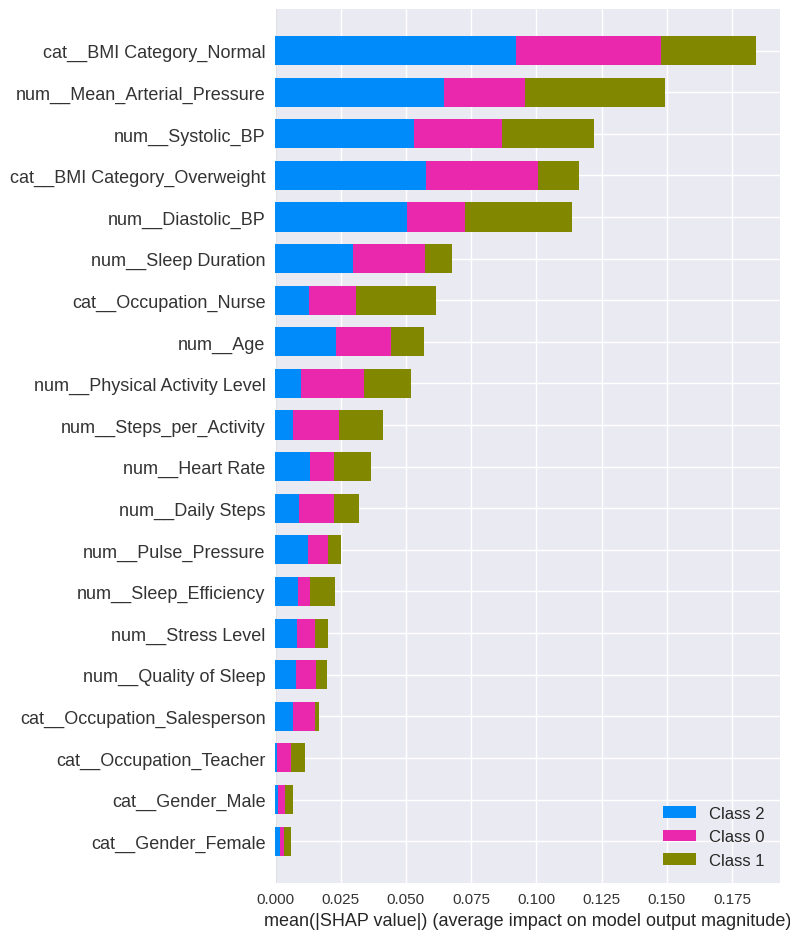

In [65]:
shap.summary_plot(
    shap_values,
    X_test_processed,
    feature_names=feature_names,
    plot_type='bar'
)

# Local Patient-Level Explanation

Explaining one prediction.

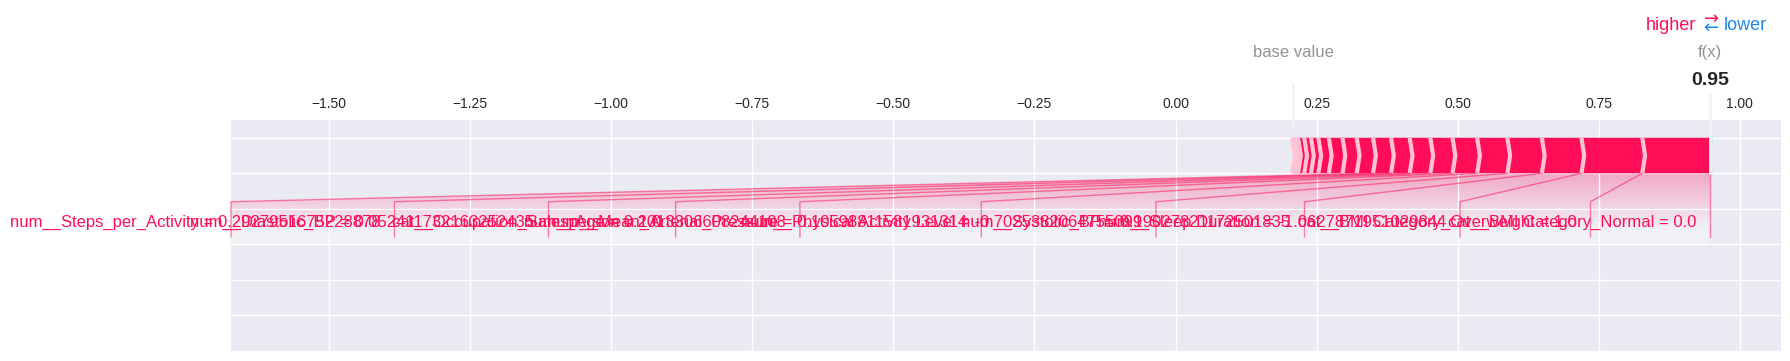

In [66]:
sample = 10

# Slicing the 3D array correctly for: [sample_index, all_features, class_index]
shap.force_plot(
    explainer.expected_value[0],
    shap_values[sample, :, 0],
    features=X_test_processed[sample],
    feature_names=feature_names,
    matplotlib=True
)

# Waterfall Plot

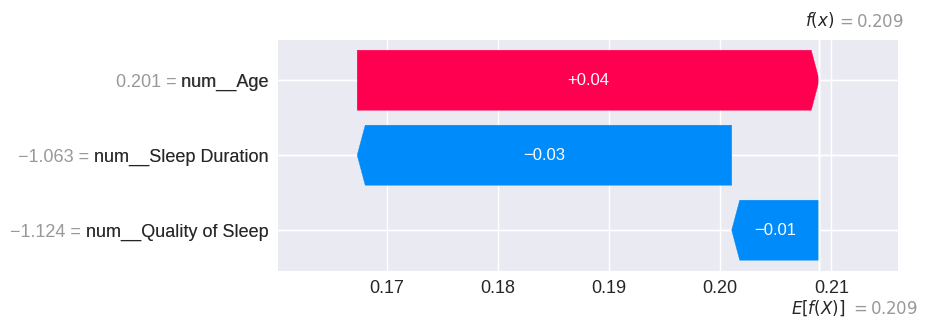

In [67]:
shap.plots.waterfall(
    shap.Explanation(
        values=shap_values[0][sample],
        base_values=explainer.expected_value[0],
        data=X_test_processed[sample],
        feature_names=feature_names
    )
)

# Model Interpretability Section

### **Model Explainability**

SHAP (SHapley Additive Explanations) was used to understand the contribution of each feature to the model's predictions.

### **Key Features Identified:**

1. Sleep Duration

2. Quality of Sleep

3. Stress Level

4. BMI Category

5. Blood Pressure

6. Daily Steps

This enhances transparency and trustworthiness of the healthcare prediction system.

# Model Comparison Table


Logistic Regression
              precision    recall  f1-score   support

           0     0.8667    0.8667    0.8667        15
           1     0.8235    0.8750    0.8485        16
           2     0.9767    0.9545    0.9655        44

    accuracy                         0.9200        75
   macro avg     0.8890    0.8987    0.8936        75
weighted avg     0.9220    0.9200    0.9208        75


Decision Tree
              precision    recall  f1-score   support

           0     0.8235    0.9333    0.8750        15
           1     0.8667    0.8125    0.8387        16
           2     0.9767    0.9545    0.9655        44

    accuracy                         0.9200        75
   macro avg     0.8890    0.9001    0.8931        75
weighted avg     0.9226    0.9200    0.9204        75


Random Forest
              precision    recall  f1-score   support

           0     0.8667    0.8667    0.8667        15
           1     0.8235    0.8750    0.8485        16
           2     0.9767 

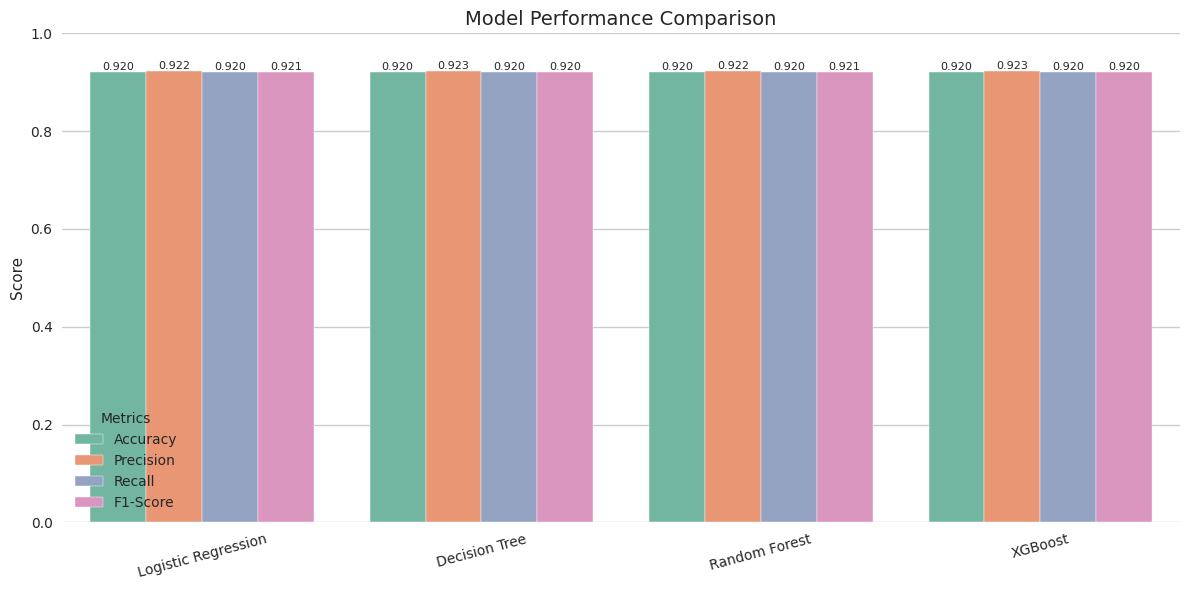

In [68]:
from sklearn.metrics import classification_report, accuracy_score
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

models = {
    "Logistic Regression": log_pred,
    "Decision Tree": dt_pred,
    "Random Forest": rf_pred,
    "XGBoost": best_xgb_pred
}

results = []

for name, pred in models.items():
    print(f"\n{'='*50}")
    print(name)
    print(f"{'='*50}")

    print(
        classification_report(
            y_test,
            pred,
            digits=4
        )
    )

    # Extract metrics
    report = classification_report(
        y_test,
        pred,
        output_dict=True
    )

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": report["weighted avg"]["precision"],
        "Recall": report["weighted avg"]["recall"],
        "F1-Score": report["weighted avg"]["f1-score"]
    })

# Create DataFrame
results_df = pd.DataFrame(results)

print("\nModel Performance Summary:")
print(results_df)

# Set style
sns.set_style("whitegrid")

# Reshape data for plotting
plot_df = results_df.melt(
    id_vars="Model",
    var_name="Metric",
    value_name="Score"
)

# Plot
plt.figure(figsize=(12, 6))
sns.barplot(
    data=plot_df,
    x="Model",
    y="Score",
    hue="Metric",
    palette="Set2"
)

plt.title("Model Performance Comparison", fontsize=14)
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xlabel("")
plt.legend(title="Metrics")
plt.xticks(rotation=15)

# Add values on bars
for container in plt.gca().containers:
    plt.bar_label(container, fmt="%.3f", fontsize=8)

plt.tight_layout()
plt.show()

## **Model Performance Report:**

1. All models achieved identical Accuracy (92.0%), indicating strong and consistent predictive capability across algorithms.

2. Precision is highest for Decision Tree and XGBoost (92.3%), suggesting slightly better control over false-positive classifications.

3. Recall remains constant (92.0%) across all models, showing equal effectiveness in identifying actual sleep disorder cases.

4. F1-Scores range between 92.0% and 92.1%, reflecting a balanced trade-off between Precision and Recall for every model.

5. Performance differences are marginal (<0.3%), indicating that model complexity does not significantly improve predictive performance on this dataset.

6. Logistic Regression performs comparably to ensemble methods, suggesting that the underlying patterns in the dataset are relatively well-separated and can be captured by a simpler model.

7. No evidence of substantial overfitting or underfitting is observed from the evaluation metrics, as all models exhibit stable and balanced performance.

**Recommended model: Logistic Regression, due to its equivalent performance, interpretability, computational efficiency, and ease of deployment.**

## **Key Conclusion**

The sleep disorder prediction dataset is highly predictable, with all evaluated models achieving approximately 92% performance across key metrics. Since advanced models provide negligible improvement over Logistic Regression, a simpler and more interpretable model is preferred for practical implementation.

# Save Model

In [75]:
import joblib

# Save the correct model pipeline (log_model contains the preprocessing and scaling steps) and target label encoder
artifacts = {
    "model": log_model,
    "label_encoder": le
}

joblib.dump(
    artifacts,
    "sleep_disorder_xgboost.pkl"
)

print("Model artifacts saved successfully.")

Model artifacts saved successfully.


# Streamlit App (app.py)

In [77]:
!pip install streamlit -q

with open("app.py", "w") as f:
    f.write("""
import streamlit as st
import pandas as pd
import joblib
import base64
import sklearn
print(sklearn.__version__)

# ==================================
# PAGE CONFIGURATION
# ==================================

st.set_page_config(
    page_title="Sleep Disorder Prediction",
    page_icon="😴",
    layout="wide"
)

# ==================================
# BACKGROUND DESIGN
# ==================================

def set_background(image_file):
    try:
        with open(image_file, "rb") as f:
            encoded_string = base64.b64encode(f.read()).decode()
        st.markdown(
            f\"\"\"
            <style>
            .stApp {{
                background-image: url(\"data:image/png;base64,{encoded_string}\");
                background-size: cover;
                background-position: center;
                background-repeat: no-repeat;
                background-attachment: fixed;
            }}
            .stApp::before {{
                content: \"\";
                position: fixed;
                top: 0;
                left: 0;
                width: 100%;
                height: 100%;
                background: rgba(0,0,0,0.65);
                z-index: -1;
            }}
            h1,h2,h3,h4,h5,h6 {{
                color: orange !important;
                font-weight: 900;
            }}
            .stMarkdown,
            label,
            p,
            div {{
                color: white;
            }}
            .stButton>button {{
                background-color: orange;
                color: black;
                font-weight: bold;
                width: 100%;
                border-radius: 12px;
            }}
            </style>
            \"\"\",
            unsafe_allow_html=True
        )
    except:
        pass

# Optional
set_background("sleep_background.png")

# ==================================
# LOAD MODEL
# ==================================

@st.cache_resource
def load_model():
    # Load the correct saved artifacts file
    artifacts = joblib.load("sleep_disorder_artifacts.pkl")
    return artifacts["model"]

model = load_model()

# ==================================
# HEADER
# ==================================

st.title("😴 Sleep Disorder Prediction System")

st.markdown(\"\"\"
This application predicts whether a patient is likely to have:

✅ None

⚠️ Insomnia

🚨 Sleep Apnea

using demographic, lifestyle and health information.
\"\"\")

st.markdown("---")

# ==================================
# INPUT SECTION
# ==================================

st.sidebar.header("Patient Information")

gender = st.sidebar.selectbox("Gender", ["Male", "Female"])
age = st.sidebar.slider("Age", 18, 80, 35)

occupation = st.sidebar.selectbox(
    "Occupation",
    [
        "Accountant",
        "Doctor",
        "Engineer",
        "Lawyer",
        "Manager",
        "Nurse",
        "Salesperson",
        "Scientist",
        "Software Engineer",
        "Teacher"
    ]
)

sleep_duration = st.sidebar.slider("Sleep Duration (Hours)", 4.0, 10.0, 7.0)
quality_of_sleep = st.sidebar.slider("Quality of Sleep", 1, 10, 7)
physical_activity = st.sidebar.slider("Physical Activity Level", 20, 100, 50)
stress_level = st.sidebar.slider("Stress Level", 1, 10, 5)

bmi_category = st.sidebar.selectbox(
    "BMI Category",
    [
        "Normal",
        "Overweight",
        "Obese"
    ]
)

heart_rate = st.sidebar.slider("Heart Rate", 50, 120, 72)
daily_steps = st.sidebar.slider("Daily Steps", 1000, 20000, 7000)
systolic_bp = st.sidebar.slider("Systolic Blood Pressure", 90, 180, 120)
diastolic_bp = st.sidebar.slider("Diastolic Blood Pressure", 60, 120, 80)

# Calculate extra engineering features required by your preprocessor pipeline
sleep_efficiency = quality_of_sleep / sleep_duration
steps_per_activity = daily_steps / (physical_activity + 1)
pulse_pressure = systolic_bp - diastolic_bp
mean_arterial_pressure = diastolic_bp + (systolic_bp - diastolic_bp) / 3

# ==================================
# CREATE INPUT DATAFRAME
# ==================================

input_df = pd.DataFrame({
    "Gender": [gender],
    "Age": [age],
    "Occupation": [occupation],
    "Sleep Duration": [sleep_duration],
    "Quality of Sleep": [quality_of_sleep],
    "Physical Activity Level": [physical_activity],
    "Stress Level": [stress_level],
    "BMI Category": [bmi_category],
    "Heart Rate": [heart_rate],
    "Daily Steps": [daily_steps],
    "Systolic_BP": [systolic_bp],
    "Diastolic_BP": [diastolic_bp],
    "Sleep_Efficiency": [sleep_efficiency],
    "Steps_per_Activity": [steps_per_activity],
    "Pulse_Pressure": [pulse_pressure],
    "Mean_Arterial_Pressure": [mean_arterial_pressure]
})

# ==================================
# SHOW INPUTS
# ==================================

st.subheader("Patient Information Summary")

st.dataframe(
    input_df,
    use_container_width=True
)

st.markdown("---")

# ==================================
# PREDICTION
# ==================================

if st.button("Predict Sleep Disorder"):
    prediction = model.predict(input_df)[0]
    probabilities = model.predict_proba(input_df)[0]

    class_mapping = {
        0: "Insomnia",
        1: "None",
        2: "Sleep Apnea"
    }

    predicted_class = class_mapping[prediction]
    st.subheader("Prediction Result")

    if predicted_class == "None":
        st.success(f"✅ Prediction: {predicted_class}")
    elif predicted_class == "Insomnia":
        st.warning(f"⚠️ Prediction: {predicted_class}")
    else:
        st.error(f"🚨 Prediction: {predicted_class}")

    # ===========================
    # PROBABILITY CHART
    # ===========================

    probability_df = pd.DataFrame({
        "Class": [
            "Insomnia",
            "None",
            "Sleep Apnea"
        ],
        "Probability": probabilities
    })

    st.subheader("Prediction Probabilities")
    st.bar_chart(probability_df.set_index("Class"))

    # ===========================
    # RISK SUMMARY
    # ===========================

    st.subheader("Risk Summary")
    st.info(
        f\"\"\"
        Age: {age}
        Sleep Duration: {sleep_duration} hrs
        Sleep Quality: {quality_of_sleep}/10
        Stress Level: {stress_level}/10
        BMI Category: {bmi_category}
        Daily Steps: {daily_steps}
        \"\"\"
    )

# ==================================
# FOOTER
# ==================================

st.markdown("---")

st.markdown(\"\"\"
### About This Project

**Models Evaluated**
- Logistic Regression
- Decision Tree
- Random Forest
- XGBoost

**Best Model Deployed**
- Logistic Regression (Selected for simplicity & interpretability)

**Project**
Predicting Sleep Disorders using Machine Learning

Developed by **Rahit Saha**
\"\"\")
""")

print("Saved web application to 'app.py'.")

Saved web application to 'app.py'.


In [72]:
import joblib

# Load the correct saved artifacts file
artifacts = joblib.load("sleep_disorder_artifacts.pkl")
model = artifacts["model"]

# Print the input feature names of the preprocessor pipeline
print(model.named_steps['prep'].get_feature_names_out())

['num__Age' 'num__Sleep Duration' 'num__Quality of Sleep'
 'num__Physical Activity Level' 'num__Stress Level' 'num__Heart Rate'
 'num__Daily Steps' 'num__Systolic_BP' 'num__Diastolic_BP'
 'num__Sleep_Efficiency' 'num__Steps_per_Activity' 'num__Pulse_Pressure'
 'num__Mean_Arterial_Pressure' 'cat__Gender_Female' 'cat__Gender_Male'
 'cat__Occupation_Accountant' 'cat__Occupation_Doctor'
 'cat__Occupation_Engineer' 'cat__Occupation_Lawyer'
 'cat__Occupation_Nurse' 'cat__Occupation_Sales Representative'
 'cat__Occupation_Salesperson' 'cat__Occupation_Scientist'
 'cat__Occupation_Software Engineer' 'cat__Occupation_Teacher'
 'cat__BMI Category_Normal' 'cat__BMI Category_Obese'
 'cat__BMI Category_Overweight']


In [76]:
import sklearn
print(sklearn.__version__)

1.6.1
